In [1]:
# version 20251124 We consider duration and modified the h definition
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
T = 60                 # horizon
N = 3                   # number of caissons

C_COPER = 15600
C_MANT = 48000
C_LEAK = 100000
K2 = 1.0    #(need to be ajusted)

# big-M
M = 3.5

U = 100                 # max total number (COPER + MANT)
P_threshold = 3.0
P_max = 3.5

b_COPER = 4
b_MANT = 5

# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2

# initial pressures 
P_init = [3.5, 3.5, 3.4]

# alpha values (example, not the real values)
alpha_init = [0.008333, 0.008333, 0.008333]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]


# ----------------------------- Model -----------------------------
mdl = Model(name='model')

# Decision variables
x = mdl.binary_var_matrix(T, N, name='x')          # COPER at t for i
y = mdl.binary_var_matrix(T, N, name='y')          # MANT at t for i
f = mdl.binary_var_matrix(T, N, name='f')          # maintenance in-progress indicator (COPER-window)
g = mdl.binary_var_matrix(T, N, name='g')          # maintenance in-progress indicator (MANT-window)
h_COPER = mdl.binary_var_matrix(T, N, name='h_COPER')  # indicates a COPER action already performed prior to t
h_MANT = mdl.binary_var_matrix(T, N, name='h_MANT')    # indicates a MANT action already performed prior to t
P = mdl.continuous_var_matrix(T, N, lb=-mdl.infinity, ub=mdl.infinity, name='P')     # pressure
v = mdl.continuous_var_matrix(T, N, lb=0.0, name='v')     # net pressure drop due to leakage

# ----------------------------- Objective -----------------------------
mdl.minimize(mdl.sum(C_COPER * x[t, i] + C_MANT * y[t, i] + K2 * C_LEAK * v[t, i] for t in range(T) for i in range(N)))

# ----------------------------- Constraints -----------------------------

# 1) initial pressure
for i in range(N):
    mdl.add_constraint(P[0, i] == P_init[i], ctname=f'initial_P_{i}')

# 2) pressure range for all t,i
for t in range(T):
    for i in range(N):
        # mdl.add_constraint(P[t, i] >= P_threshold, ctname=f'P_lower_{t}_{i}')
        mdl.add_constraint(P[t, i] <= P_max, ctname=f'P_upper_{t}_{i}')

# 3) P restores to P_max after COPER (for t such that t + b_COPER < T)
for t in range(T):
    for i in range(N):
        if t + b_COPER < T:
            mdl.add_constraint(P[t + b_COPER, i] >= P_max - M * (1 - x[t, i]), ctname=f'afterCOPER_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_COPER, i] <= P_max + M * (1 - x[t, i]), ctname=f'afterCOPER_ub_{t}_{i}')

# 4) P restores to P_max after MANT
for t in range(T):
    for i in range(N):
        if t + b_MANT < T:
            mdl.add_constraint(P[t + b_MANT, i] >= P_max - M * (1 - y[t, i]), ctname=f'afterMANT_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_MANT, i] <= P_max + M * (1 - y[t, i]), ctname=f'afterMANT_ub_{t}_{i}')

# 5) h_COPER and h_MANT definitions
for t in range(T):
    for i in range(N):

        # ======================= COPER =======================
        # Case 1 for COPER: t < b_COPER => h must be 0
        if t < b_COPER:
            mdl.add_constraint(h_COPER[t, i] == 0, ctname=f'hCOPER_zero_{t}_{i}')
        else:
            # Case 2 for COPER: h[t] >= x[s] for all s with s + b_COPER <= t
            for s in range(0, t - b_COPER + 1):
                mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')

            # Case 3 for COPER: h[t] <= sum x[0 .. t - b_COPER]
            mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t - b_COPER + 1)), ctname=f'hCOPER_ub_{t}_{i}')

        # ======================= MANT =========================
        # Case 1 for MANT: t < b_MANT => h must be 0
        if t < b_MANT:
            mdl.add_constraint(h_MANT[t, i] == 0, ctname=f'hMANT_zero_{t}_{i}')
        else:
            # Case 2 for MANT: h[t] >= y[s] for all s with s + b_MANT <= t
            for s in range(0, t - b_MANT + 1):
                mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')

            # Case 3 for MANT: h[t] <= sum y[0 .. t - b_MANT]
            mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t - b_MANT + 1)), ctname=f'hMANT_ub_{t}_{i}')





# 6) Degradation rate switch (use h_COPER/h_MANT to pick alpha)
for t in range(T-1):
    for i in range(N):
        # 1. f[t,i]=1 : keep same value
        mdl.add_constraint(P[t+1,i] - P[t,i] <= M * (1 - f[t,i]))
        mdl.add_constraint(P[t,i] - P[t+1,i] <= M * (1 - f[t,i]))
        
        # 2. f[t,i]=0, h_COPER[t,i]=1 : decrease by alpha_COPER
        mdl.add_constraint(P[t+1,i] >= (1-alpha_COPER[i]) * P[t,i] - M * (1-h_COPER[t,i] + f[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_COPER[i]) * P[t,i] + M * (1-h_COPER[t,i] + f[t,i]))
        
        # 3. f[t,i]=0, h_COPER[t,i]=0 : decrease by alpha_init
        mdl.add_constraint(P[t+1,i] >= (1-alpha_init[i]) * P[t,i] - M * (h_COPER[t,i] + f[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_init[i]) * P[t,i] + M * (h_COPER[t,i] + f[t,i]))
for t in range(T-1):
    for i in range(N):
        # 1. g[t,i]=1 : keep same value
        mdl.add_constraint(P[t+1,i] - P[t,i] <= M * (1 - g[t,i]))
        mdl.add_constraint(P[t,i] - P[t+1,i] <= M * (1 - g[t,i]))
        
        # 2. g[t,i]=0, h_MANT[t,i]=1 : decrease by alpha_MANT
        mdl.add_constraint(P[t+1,i] >= (1-alpha_MANT[i]) * P[t,i] - M * (1-h_MANT[t,i] + g[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_MANT[i]) * P[t,i] + M * (1-h_MANT[t,i] + g[t,i]))
        
        # 3. g[t,i]=0, h_MANT[t,i]=0 : decrease by alpha_init
        mdl.add_constraint(P[t+1,i] >= (1-alpha_init[i]) * P[t,i] - M * (h_MANT[t,i] + g[t,i]))
        mdl.add_constraint(P[t+1,i] <= (1-alpha_init[i]) * P[t,i] + M * (h_MANT[t,i] + g[t,i]))


# 7) Pressure stays stable during maintenance


# 8) f, g indicates whether a maintenance is in progress
#    f[t,i] >= x[t-k,i]  for k=0..b_COPER-1  and  f[t,i] <= sum_{k=0..b_COPER-1} x[t-k,i]
for t in range(T):
    for i in range(N):
        # lower bounds: if any start in window, f[t,i] >= that start
        for k in range(0, b_COPER):
            s = t - k
            if s >= 0:
                mdl.add_constraint(f[t, i] >= x[s, i], ctname=f'f_lb_{t}_{i}_from_{s}')
        # upper bound
        idxs = [t - k for k in range(0, b_COPER) if (t - k) >= 0]
        if idxs:
            mdl.add_constraint(f[t, i] <= mdl.sum(x[s, i] for s in idxs), ctname=f'f_ub_{t}_{i}')
        else:
            # no s in window => f <= 0
            mdl.add_constraint(f[t, i] <= 0, ctname=f'f_ub_empty_{t}_{i}')

#    same for g with b_MANT window
for t in range(T):
    for i in range(N):
        for k in range(0, b_MANT):
            s = t - k
            if s >= 0:
                mdl.add_constraint(g[t, i] >= y[s, i], ctname=f'g_lb_{t}_{i}_from_{s}')
        idxs = [t - k for k in range(0, b_MANT) if (t - k) >= 0]
        if idxs:
            mdl.add_constraint(g[t, i] <= mdl.sum(y[s, i] for s in idxs), ctname=f'g_ub_{t}_{i}')
        else:
            mdl.add_constraint(g[t, i] <= 0, ctname=f'g_ub_empty_{t}_{i}')

# 9) net pressure drop: v definition
for t in range(1, T):
    for i in range(N):
        mdl.add_constraint(v[t, i] >= P[t-1, i] - P[t, i], ctname=f'v_def_{t}_{i}')
        mdl.add_constraint(v[t, i] >= 0, ctname=f'v_nonneg_{t}_{i}')

# 10) Total operation number
mdl.add_constraint(mdl.sum(x[t, i] + y[t, i] for t in range(T) for i in range(N)) <= U, ctname='total_ops')

# (Optional) 11) Prevent overlapping starts
# for i in range(N):
#     for t in range(T):
#         for s in range(T):
#             if s < t and (s + b_COPER >= t):
#                 mdl.add_constraint(x[t,i] + x[s,i] <= 1, ctname=f'no_overlap_coper_{t}_{s}_{i}')
#             if s < t and (s + b_MANT >= t):
#                 mdl.add_constraint(y[t,i] + y[s,i] <= 1, ctname=f'no_overlap_mant_{t}_{s}_{i}')

# 11) Single decision at a time for each caisson
for t in range(T):
    for i in range(N):
        mdl.add_constraint(x[t, i] + y[t, i] <= 1, ctname=f'single_decision_{t}_{i}')
# ----------------------------- Solve -----------------------------
# mdl.parameters.timelimit = 300
solution = mdl.solve(log_output=True)

# Print solution summary if found
if solution:
    print("Objective value:", solution.objective_value)
    # print some pressure values for first caisson as example
    for i in range(N):
        ps = [P[t, i].solution_value for t in range(min(T, 30))]
        xs = [x[t, i].solution_value for t in range(min(T, 30))]
        ys = [y[t, i].solution_value for t in range(min(T, 30))]
        fs = [f[t, i].solution_value for t in range(min(T, 30))]
        gs = [g[t, i].solution_value for t in range(min(T, 30))]
        hs_c = [h_COPER[t, i].solution_value for t in range(min(T, 30))]
        hs_m = [h_MANT[t, i].solution_value for t in range(min(T, 30))]
        vs = [v[t, i].solution_value for t in range(min(T, 30))]
        print(f"\nCaisson {i}:")
        print("P[0..29]  :", ps)
        print("x[0..29]  :", xs)
        print("y[0..29]  :", ys)
        print("f[0..29]  :", fs)
        print("g[0..29]  :", gs)
        print("h_COPER.. :", hs_c)
        print("h_MANT... :", hs_m)
        print("v[0..29]  :", vs)
else:
    print("No solution found. Analyzing conflicts...")

    # get CPLEX object
    cpx = mdl.get_cplex()

    # disable solver output
    cpx.set_results_stream(None)
    cpx.set_warning_stream(None)
    cpx.set_log_stream(None)

    # run conflict analysis
    cpx.conflict.refine()

    # write conflict analysis results to file
    conflict_file = "conflict_results.txt"
    cpx.conflict.write(conflict_file)
    print(f"Conflict analysis report written to '{conflict_file}'")



Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Tried aggregator 7 times.
MIP Presolve eliminated 5520 rows and 305 columns.
MIP Presolve modified 7765 coefficients.
Aggregator did 84 substitutions.
Reduced MIP has 9604 rows, 1051 columns, and 28618 nonzeros.
Reduced MIP has 783 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.55 sec. (557.80 ticks)
Found incumbent of value 405225.959709 after 0.56 sec. (561.87 ticks)
Probing fixed 156 vars, tightened 107 bounds.
Probing changed sense of 159 constraints.
Probing time = 0.08 sec. (41.13 ticks)
Tried aggregator 6 times.
MIP Presolve eliminated 7858 rows and 633 columns.
MIP Presolve modified 5035 coefficients.
Aggregator did 66 substitutions.
Reduced MIP has 1680 rows, 352 columns, and 5090 nonzeros.
Reduced MIP has 256 binaries, 0 generals, 0 SOSs, and 0 indicators.
Presolve time = 0.31 sec. (238.63 ticks)
Probing fixed 244 vars, tightened 148 bounds.
Probing chan

In [ ]:
# version 20251123 h definition problem
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
T = 20                 # horizon
N = 3                   # number of caissons

C_COPER = 15600
C_MANT = 48000
C_LEAK = 100000
K2 = 1.0    #(need to be ajusted)

# big-M
M = 3.5

U = 100                 # max total number (COPER + MANT)
P_threshold = 3.0
P_max = 3.5

b_COPER = 4
b_MANT = 5

# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2

# initial pressures 
P_init = [3.5, 3.5, 3.4]

# alpha values (example, not the real values)
alpha_init = [0.008333, 0.008333, 0.008333]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]


# ----------------------------- Model -----------------------------
mdl = Model(name='model')

# Decision variables
x = mdl.binary_var_matrix(T, N, name='x')          # COPER at t for i
y = mdl.binary_var_matrix(T, N, name='y')          # MANT at t for i
f = mdl.binary_var_matrix(T, N, name='f')          # maintenance in-progress indicator (COPER-window)
g = mdl.binary_var_matrix(T, N, name='g')          # maintenance in-progress indicator (MANT-window)
h_COPER = mdl.binary_var_matrix(T, N, name='h_COPER')  # indicates a COPER action already performed prior to t
h_MANT = mdl.binary_var_matrix(T, N, name='h_MANT')    # indicates a MANT action already performed prior to t
P = mdl.continuous_var_matrix(T, N, lb=-mdl.infinity, ub=mdl.infinity, name='P')     # pressure
v = mdl.continuous_var_matrix(T, N, lb=0.0, name='v')     # net pressure drop due to leakage

# ----------------------------- Objective -----------------------------
mdl.minimize(mdl.sum(C_COPER * x[t, i] + C_MANT * y[t, i] + K2 * C_LEAK * v[t, i] for t in range(T) for i in range(N)))

# ----------------------------- Constraints -----------------------------

# 1) initial pressure
for i in range(N):
    mdl.add_constraint(P[0, i] == P_init[i], ctname=f'initial_P_{i}')

# 2) pressure range for all t,i
for t in range(T):
    for i in range(N):
        mdl.add_constraint(P[t, i] >= P_threshold, ctname=f'P_lower_{t}_{i}')
        mdl.add_constraint(P[t, i] <= P_max, ctname=f'P_upper_{t}_{i}')

# 3) P restores to P_max after COPER (for t such that t + b_COPER < T)
for t in range(T):
    for i in range(N):
        if t + b_COPER < T:
            mdl.add_constraint(P[t + b_COPER, i] >= P_max - M * (1 - x[t, i]), ctname=f'afterCOPER_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_COPER, i] <= P_max + M * (1 - x[t, i]), ctname=f'afterCOPER_ub_{t}_{i}')

# 4) P restores to P_max after MANT
for t in range(T):
    for i in range(N):
        if t + b_MANT < T:
            mdl.add_constraint(P[t + b_MANT, i] >= P_max - M * (1 - y[t, i]), ctname=f'afterMANT_lb_{t}_{i}')
            mdl.add_constraint(P[t + b_MANT, i] <= P_max + M * (1 - y[t, i]), ctname=f'afterMANT_ub_{t}_{i}')

# 5) h_COPER and h_MANT definitions
# h_{t,i} >= x_{s,i} for all s < t  AND  h_{t,i} <= sum_{s=0}^{t-1} x_{s,i}
# for t in range(T):
#     for i in range(N):
#         # lower bounds: for all s < t, h >= x[s,i]
#         for s in range(0, t):   # empty when t=0
#             mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')
#             mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')
#         # upper bounds: h <= sum_{s=0}^{t-1} x[s,i]
#         if t == 0:
#             # sum over empty set = 0
#             mdl.add_constraint(h_COPER[t, i] <= 0, ctname=f'hCOPER_ub_{t}_{i}_empty')
#             mdl.add_constraint(h_MANT[t, i] <= 0, ctname=f'hMANT_ub_{t}_{i}_empty')
#         else:
#             mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t)), ctname=f'hCOPER_ub_{t}_{i}')
#             mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t)), ctname=f'hMANT_ub_{t}_{i}')


for t in range(T):
    for i in range(N):

        # ======================= COPER =======================
        # Case 1 for COPER: t < b_COPER => h must be 0
        if t < b_COPER:
            mdl.add_constraint(h_COPER[t, i] == 0, ctname=f'hCOPER_zero_{t}_{i}')
        else:
            # Case 2 for COPER: h[t] >= x[s] for all s with s + b_COPER <= t
            for s in range(0, t - b_COPER + 1):
                mdl.add_constraint(h_COPER[t, i] >= x[s, i], ctname=f'hCOPER_ge_x_{t}_{i}_from_{s}')

            # Case 3 for COPER: h[t] <= sum x[0 .. t - b_COPER]
            mdl.add_constraint(h_COPER[t, i] <= mdl.sum(x[s, i] for s in range(0, t - b_COPER + 1)), ctname=f'hCOPER_ub_{t}_{i}')

        # ======================= MANT =========================
        # Case 1 for MANT: t < b_MANT => h must be 0
        if t < b_MANT:
            mdl.add_constraint(h_MANT[t, i] == 0, ctname=f'hMANT_zero_{t}_{i}')
        else:
            # Case 2 for MANT: h[t] >= y[s] for all s with s + b_MANT <= t
            for s in range(0, t - b_MANT + 1):
                mdl.add_constraint(h_MANT[t, i] >= y[s, i], ctname=f'hMANT_ge_y_{t}_{i}_from_{s}')

            # Case 3 for MANT: h[t] <= sum y[0 .. t - b_MANT]
            mdl.add_constraint(h_MANT[t, i] <= mdl.sum(y[s, i] for s in range(0, t - b_MANT + 1)), ctname=f'hMANT_ub_{t}_{i}')





# 6) Degradation rate switch (use h_COPER/h_MANT to pick alpha)
for t in range(T - 1):
    for i in range(N):
        # when h_COPER[t,i] = 1 -> P[t+1] approx (1-alpha_COPER) * P[t]
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_COPER[i]) * P[t, i] - M * (1 - h_COPER[t, i]), ctname=f'PE_hCOPER_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_COPER[i]) * P[t, i] + M * (1 - h_COPER[t, i]), ctname=f'PE_hCOPER_ub_{t}_{i}')

        # when h_MANT[t,i] = 1 -> P[t+1] approx (1-alpha_MANT) * P[t]
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_MANT[i]) * P[t, i] - M * (1 - h_MANT[t, i]), ctname=f'PE_hMANT_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_MANT[i]) * P[t, i] + M * (1 - h_MANT[t, i]), ctname=f'PE_hMANT_ub_{t}_{i}')

        # when h_COPER==0 and h_MANT==0
        mdl.add_constraint(P[t + 1, i] >= (1 - alpha_init[i]) * P[t, i] - M * (h_COPER[t, i] + h_MANT[t, i]), ctname=f'PE_0_lb_{t}_{i}')
        mdl.add_constraint(P[t + 1, i] <= (1 - alpha_init[i]) * P[t, i] + M * (h_COPER[t, i] + h_MANT[t, i]), ctname=f'PE_0_ub_{t}_{i}')

# 7) Pressure stays stable during maintenance
# #    For each start x[t,i]==1, for k=1..b_COPER-1 enforce P[t+k,i] == P[t,i]
# for t in range(T):
#     for i in range(N):
#         for k in range(1, b_COPER):
#             if t + k < T:
#                 mdl.add_constraint(P[t + k, i] >= P[t, i] - M * (1 - x[t, i]), ctname=f'COPER_hold_lb_{t}_{i}_k{k}')
#                 mdl.add_constraint(P[t + k, i] <= P[t, i] + M * (1 - x[t, i]), ctname=f'COPER_hold_ub_{t}_{i}_k{k}')

# #    For MANT windows
# for t in range(T):
#     for i in range(N):
#         for k in range(1, b_MANT):
#             if t + k < T:
#                 mdl.add_constraint(P[t + k, i] >= P[t, i] - M * (1 - y[t, i]), ctname=f'MANT_hold_lb_{t}_{i}_k{k}')
#                 mdl.add_constraint(P[t + k, i] <= P[t, i] + M * (1 - y[t, i]), ctname=f'MANT_hold_ub_{t}_{i}_k{k}')

# 8) f, g indicates whether a maintenance is in progress
# #    f[t,i] >= x[t-k,i]  for k=0..b_COPER-1  and  f[t,i] <= sum_{k=0..b_COPER-1} x[t-k,i]
# for t in range(T):
#     for i in range(N):
#         # lower bounds: if any start in window, f[t,i] >= that start
#         for k in range(0, b_COPER):
#             s = t - k
#             if s >= 0:
#                 mdl.add_constraint(f[t, i] >= x[s, i], ctname=f'f_lb_{t}_{i}_from_{s}')
#         # upper bound
#         idxs = [t - k for k in range(0, b_COPER) if (t - k) >= 0]
#         if idxs:
#             mdl.add_constraint(f[t, i] <= mdl.sum(x[s, i] for s in idxs), ctname=f'f_ub_{t}_{i}')
#         else:
#             # no s in window => f <= 0
#             mdl.add_constraint(f[t, i] <= 0, ctname=f'f_ub_empty_{t}_{i}')

# #    same for g with b_MANT window
# for t in range(T):
#     for i in range(N):
#         for k in range(0, b_MANT):
#             s = t - k
#             if s >= 0:
#                 mdl.add_constraint(g[t, i] >= y[s, i], ctname=f'g_lb_{t}_{i}_from_{s}')
#         idxs = [t - k for k in range(0, b_MANT) if (t - k) >= 0]
#         if idxs:
#             mdl.add_constraint(g[t, i] <= mdl.sum(y[s, i] for s in idxs), ctname=f'g_ub_{t}_{i}')
#         else:
#             mdl.add_constraint(g[t, i] <= 0, ctname=f'g_ub_empty_{t}_{i}')

# 9) net pressure drop: v definition
for t in range(1, T):
    for i in range(N):
        mdl.add_constraint(v[t, i] >= P[t-1, i] - P[t, i], ctname=f'v_def_{t}_{i}')
        mdl.add_constraint(v[t, i] >= 0, ctname=f'v_nonneg_{t}_{i}')

# 10) Total operation number
mdl.add_constraint(mdl.sum(x[t, i] + y[t, i] for t in range(T) for i in range(N)) <= U, ctname='total_ops')

# (Optional) 11) Prevent overlapping starts
# for i in range(N):
#     for t in range(T):
#         for s in range(T):
#             if s < t and (s + b_COPER >= t):
#                 mdl.add_constraint(x[t,i] + x[s,i] <= 1, ctname=f'no_overlap_coper_{t}_{s}_{i}')
#             if s < t and (s + b_MANT >= t):
#                 mdl.add_constraint(y[t,i] + y[s,i] <= 1, ctname=f'no_overlap_mant_{t}_{s}_{i}')

# ----------------------------- Solve -----------------------------
# mdl.parameters.timelimit = 300
solution = mdl.solve(log_output=True)

# Print solution summary if found
if solution:
    print("Objective value:", solution.objective_value)
    # print some pressure values for first caisson as example
    for i in range(N):
        ps = [P[t, i].solution_value for t in range(min(T, 30))]
        xs = [x[t, i].solution_value for t in range(min(T, 30))]
        ys = [y[t, i].solution_value for t in range(min(T, 30))]
        fs = [f[t, i].solution_value for t in range(min(T, 30))]
        gs = [g[t, i].solution_value for t in range(min(T, 30))]
        hs_c = [h_COPER[t, i].solution_value for t in range(min(T, 30))]
        hs_m = [h_MANT[t, i].solution_value for t in range(min(T, 30))]
        vs = [v[t, i].solution_value for t in range(min(T, 30))]
        print(f"\nCaisson {i}:")
        print("P[0..29]  :", ps)
        print("x[0..29]  :", xs)
        print("y[0..29]  :", ys)
        print("f[0..29]  :", fs)
        print("g[0..29]  :", gs)
        print("h_COPER.. :", hs_c)
        print("h_MANT... :", hs_m)
        print("v[0..29]  :", vs)
else:
    print("No solution found. Analyzing conflicts...")

    # get CPLEX object
    cpx = mdl.get_cplex()

    # disable solver output
    cpx.set_results_stream(None)
    cpx.set_warning_stream(None)
    cpx.set_log_stream(None)

    # run conflict analysis
    cpx.conflict.refine()

    # write conflict analysis results to file
    conflict_file = "conflict_results.txt"
    cpx.conflict.write(conflict_file)
    print(f"Conflict analysis report written to '{conflict_file}'")



Version identifier: 22.1.1.0 | 2022-11-27 | 9160aff4d
CPXPARAM_Read_DataCheck                          1
Row 'PE_0_ub_14_2' infeasible, all entries at implied bounds.
Presolve time = 0.00 sec. (0.89 ticks)

Root node processing (before b&c):
  Real time             =    0.01 sec. (1.06 ticks)
Parallel b&c, 8 threads:
  Real time             =    0.00 sec. (0.00 ticks)
  Sync time (average)   =    0.00 sec.
  Wait time (average)   =    0.00 sec.
                          ------------
Total (root+branch&cut) =    0.01 sec. (1.06 ticks)
No solution found. Analyzing conflicts...
Conflict analysis report written to 'conflict_results.txt'


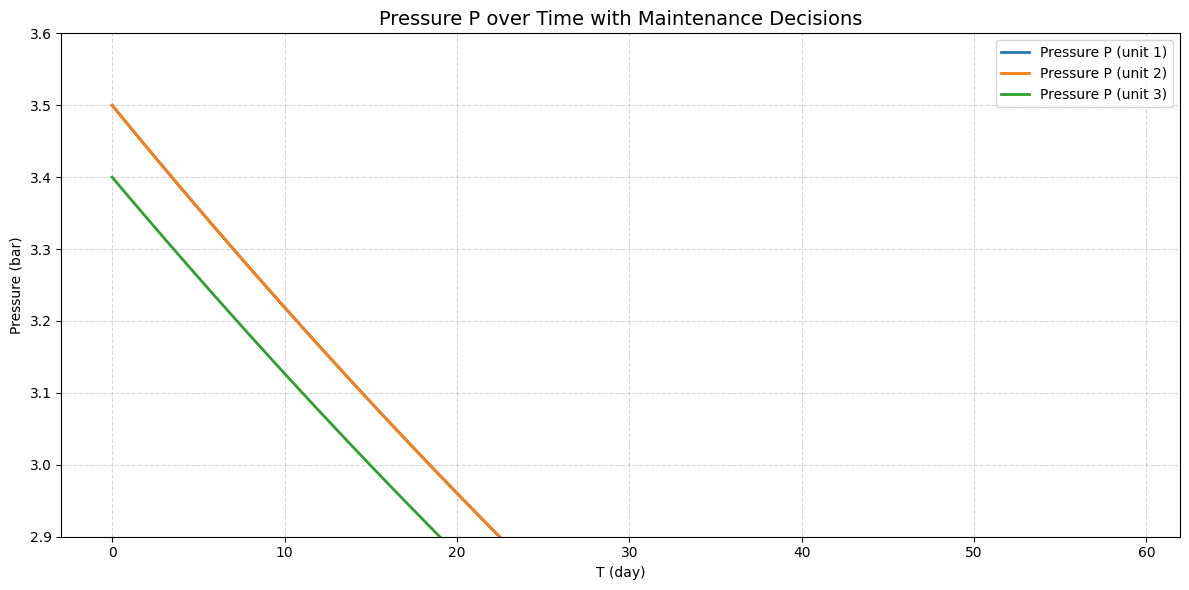

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

if solution:
    # extract solution values
    P_sol = np.zeros((T, N))
    x_sol = np.zeros((T, N))
    y_sol = np.zeros((T, N))

    for t in range(T):
        for i in range(N):
            P_sol[t, i] = P[t, i].solution_value
            x_sol[t, i] = x[t, i].solution_value
            y_sol[t, i] = y[t, i].solution_value

    # plotting
    plt.figure(figsize=(12, 6))
    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for i in range(N):
        plt.plot(range(T), P_sol[:, i], label=f'Pressure P (unit {i+1})', color=colors[i], lw=2)

        # mark COPER times
        coper_times = [t for t in range(T) if x_sol[t, i] > 0.5]
        for t in coper_times:
            plt.axvline(t, color=colors[i], linestyle='--', alpha=0.4)
            plt.text(t, P_max-0.05, f'C{i+1}', rotation=90, fontsize=8, color=colors[i])

        # mark MANT times
        mant_times = [t for t in range(T) if y_sol[t, i] > 0.5]
        for t in mant_times:
            plt.axvline(t, color=colors[i], linestyle=':', alpha=0.6)
            plt.text(t, P_max-0.15, f'M{i+1}', rotation=90, fontsize=8, color=colors[i])

    plt.title("Pressure P over Time with Maintenance Decisions", fontsize=14)
    plt.xlabel("T (day)")
    plt.ylabel("Pressure (bar)")
    plt.ylim(P_threshold-0.1, P_max+0.1)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [ ]:
import plotly.graph_objects as go
import numpy as np

if solution:
    # extract solution values
    P_sol = np.zeros((T, N))
    x_sol = np.zeros((T, N))
    y_sol = np.zeros((T, N))

    for t in range(T):
        for i in range(N):
            P_sol[t, i] = P[t, i].solution_value
            x_sol[t, i] = x[t, i].solution_value
            y_sol[t, i] = y[t, i].solution_value

    # create interactive plot
    fig = go.Figure()

    colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # colors for three units

    for i in range(N):
        # pressure curve
        fig.add_trace(go.Scatter(
            x=list(range(T)),
            y=P_sol[:, i],
            mode='lines',
            name=f'Pressure - Unit {i+1}',
            line=dict(width=2, color=colors[i])
        ))

        # COPER maintenance points
        coper_times = [t for t in range(T) if x_sol[t, i] > 0.5]
        fig.add_trace(go.Scatter(
            x=coper_times,
            y=[P_sol[t, i] for t in coper_times],
            mode='markers',
            name=f'COPER - Unit {i+1}',
            marker=dict(symbol='triangle-up', color=colors[i], size=10, line=dict(width=1, color='black'))
        ))

        # MANT maintenance points
        mant_times = [t for t in range(T) if y_sol[t, i] > 0.5]
        fig.add_trace(go.Scatter(
            x=mant_times,
            y=[P_sol[t, i] for t in mant_times],
            mode='markers',
            name=f'MANT - Unit {i+1}',
            marker=dict(symbol='star', color=colors[i], size=10, line=dict(width=1, color='black'))
        ))

    # threshold lines
    fig.add_hline(y=P_threshold, line_dash="dot", line_color="red", annotation_text="Threshold")
    fig.add_hline(y=P_max, line_dash="dot", line_color="green", annotation_text="P_max")

    # layout
    fig.update_layout(
        title="Pressure P over Time with Maintenance Decisions",
        xaxis_title="T (day)",
        yaxis_title="Pressure (bar)",
        legend_title="Legend",
        template="plotly_white",
        hovermode="x unified",
        width=1000,
        height=600
    )

    fig.show()
else:
    print("❌ No solution found. Cannot plot results.")


In [ ]:
# cplex version: nb if variables exceeded.
from docplex.mp.model import Model

# ----------------------------- Parameters -----------------------------
N = 3              # nb of CSEM
J = 20             # nb of tasks
T = 360              # total time
C_COPER = 15600        # COPER action cost
C_MANT = 48000         # MANT action cost
C_leak = 100000 * 25200         # leakage cost per kg SF6
b_COPER = 4        # COPER operation duration
b_MANT = 50         # MANT operation duration
M1 = 400             # Big-M constant
M2 = 1e10
# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2
# alpha values (example, not the real values)
alpha_init = [0.005,0.006, 0.0045]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]
# initial pressures 
P_init = [3.5, 3.5, 3.4]
# Volume
V = [1, 1, 1]

# coefficient to translate pressure to leakage mass
K = []
for i in range(N):
    K.append(10**2 * 146 * V[i] / (8.314 * 293.15))

# Basic CR leakage cost
B_CR = []
for i in range(N):
    B_CR.append((T*alpha_init[i]/(3.5-3.2)) * K[i] * C_leak)
    

mdl = Model('gas_system_maintenance')

# decision variables
x_COPER = mdl.binary_var_matrix(N,J, name='x_COPER')
x_MANT = mdl.binary_var_matrix(N, J, name='x_MANT')
y_COPER = mdl.continuous_var_matrix(N, J,lb=0, name='y_COPER')  # product x R_COPER
y_MANT = mdl.continuous_var_matrix(N, J,lb=0, name='y_MANT')      # product x R_MANT
t = mdl.integer_var_matrix(N, J, name='t')
z = mdl.binary_var_cube(N, J, J, name='z')
t_END = mdl.integer_var_matrix(N, J, name='t_END')
alpha_eff = mdl.continuous_var_matrix(N, J, name='alpha_eff')  # effective alpha after task k for CSEM i
R_COPER = mdl.continuous_var_matrix(N, J, name='R_COPER')   # cost reduction due to COPER
R_MANT = mdl.continuous_var_matrix(N, J, name='R_MANT')   # cost reduction due to MANT


# # non overlapping constraints
# for i in range(N):
#     for k in range(J):
#         for l in range(J):
#             if k != l:
#                 mdl.add(t[i,k] + b_COPER* x_COPER[i,k] + b_MANT*x_MANT[i,k] <= t[i,l] + M1*(1-z[i,k,l]))
#                 mdl.add(t[i,l] + b_MANT*x_MANT[i,l] + b_COPER*x_COPER[i,l] <= t[i,k] + M1*z[i,k,l])

# each CSEM can have at most one task COPER or MANT
for i in range(N):
    mdl.add(mdl.sum(x_COPER[i,k] + x_MANT[i,k] for k in range(J)) <= 1)

# Event end times
for i in range(N):
    for k in range(J):
        mdl.add(t_END[i,k] == t[i,k] + b_COPER*x_COPER[i,k] + b_MANT*x_MANT[i,k])
    
# Effective leakage rate
for i in range(N):
    for k in range(J):
        mdl.add(alpha_eff[i,k] == alpha_COPER[i] * x_COPER[i,k] + alpha_MANT[i] * x_MANT[i,k] + alpha_init[i] * (1 - x_COPER[i,k] - x_MANT[i,k]))

# # contains only complete events
# for i in range(N):
#     for k in range(J):
#         mdl.add(t_END[i,k] <= T + M * (1 - x_COPER[i,k] - x_MANT[i,k]))

# Cost reduction due to COPER/MANT
for i in range(N):
    for k in range(J):
        mdl.add(R_COPER[i,k] == C_leak * K[i] * (alpha_init[i] - alpha_COPER[i])* (T- t_END[i,k]))
        mdl.add(R_MANT[i,k] == C_leak * K[i] * (alpha_init[i] - alpha_MANT[i])* (T- t_END[i,k]))

# y definition
for i in range(N):
    for k in range(J):
        mdl.add(y_COPER[i,k] <= M2 * x_COPER[i,k])
        mdl.add(y_COPER[i,k] <= R_COPER[i,k])
        mdl.add(y_COPER[i,k] >= R_COPER[i,k] - M2 * (1 - x_COPER[i,k]))
        mdl.add(y_MANT[i,k] >= 0)

        mdl.add(y_MANT[i,k] <= M2 * x_MANT[i,k])
        mdl.add(y_MANT[i,k] <= R_MANT[i,k])
        mdl.add(y_MANT[i,k] >= R_MANT[i,k] - M2 * (1 - x_MANT[i,k])) 
        mdl.add(y_MANT[i,k] >= 0)
    
        
# objective function
action_cost = mdl.sum(C_COPER*x_COPER[i,k] + C_MANT*x_MANT[i,k] for i in range(N) for k in range(J))
BasicCR_cost = mdl.sum(B_CR[i] for i in range(N))
leakage_cost_reduction = mdl.sum(y_COPER[i,k] + y_MANT[i,k] for i in range(N) for k in range(J))

mdl.minimize(action_cost + BasicCR_cost - leakage_cost_reduction)

# solve the model
sol = mdl.solve()
if sol:
    print('Objective value:', sol.objective_value)
    
    # print COPER and MANT scheduling
    for i in range(N):
        print(f"\nCSEM {i}:")
        print("COPER events:")
        for k in range(J):
            if x_COPER[i, k].solution_value > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].solution_value:.2f} units")
        print("MANT events:")
        for k in range(J):
            if x_MANT[i, k].solution_value > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].solution_value:.2f} units")
else:
    print("No solution found.")



DOcplexLimitsExceeded: **** Promotional version. Problem size limits (1000 vars, 1000 consts) exceeded, model has 1740 vars, 723 consts, CPLEX code=1016

In [ ]:
# event-based model, Gurobi version
# one task per CSEM, no automatic alpha switch

from gurobipy import Model, GRB, quicksum

# ----------------------------- Parameters -----------------------------
N = 3              # number of CSEM
J = 20             # number of tasks
T = 360            # total time
C_COPER = 15600    # COPER action cost
C_MANT = 48000     # MANT action cost
C_leak = 100000 * 25200  # leakage cost per kg SF6
b_COPER = 4        # COPER operation duration
b_MANT = 50        # MANT operation duration
M1 = 400           # Big-M constant
M2 = 1e10          # Big-M for y definition

# improvement factors
mu_COPER = 1.6
mu_MANT = 4.2

# alpha values
alpha_init = [0.005,0.006, 0.0045]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]

# initial pressures 
P_init = [3.5, 3.5, 3.4]
# Volume
V = [1, 1, 1]

# coefficient to translate pressure to leakage mass
K = [10**2 * 146 * V[i] / (8.314 * 293.15) for i in range(N)]

# Basic CR leakage cost
B_CR = [(T*alpha_init[i]/(3.5-3.2)) * K[i] * C_leak for i in range(N)]

# ----------------------------- Model -----------------------------
mdl = Model('gas_system_maintenance')

# decision variables
x_COPER = mdl.addVars(N, J, vtype=GRB.BINARY, name='x_COPER')
x_MANT = mdl.addVars(N, J, vtype=GRB.BINARY, name='x_MANT')
y_COPER = mdl.addVars(N, J, lb=0, name='y_COPER')
y_MANT = mdl.addVars(N, J, lb=0, name='y_MANT')
t = mdl.addVars(N, J, vtype=GRB.INTEGER, name='t')
t_END = mdl.addVars(N, J, vtype=GRB.INTEGER, name='t_END')
alpha_eff = mdl.addVars(N, J, name='alpha_eff')
R_COPER = mdl.addVars(N, J, name='R_COPER')
R_MANT = mdl.addVars(N, J, name='R_MANT')

# ----------------------------- Constraints -----------------------------
# Each CSEM can have at most one task
for i in range(N):
    mdl.addConstr(quicksum(x_COPER[i, k] + x_MANT[i, k] for k in range(J)) <= 1)

# Event end times
for i in range(N):
    for k in range(J):
        mdl.addConstr(t_END[i, k] == t[i, k] + b_COPER * x_COPER[i, k] + b_MANT * x_MANT[i, k])

# Effective leakage rate
for i in range(N):
    for k in range(J):
        mdl.addConstr(alpha_eff[i, k] == alpha_COPER[i] * x_COPER[i, k] + 
                      alpha_MANT[i] * x_MANT[i, k] + 
                      alpha_init[i] * (1 - x_COPER[i, k] - x_MANT[i, k]))

# Cost reduction due to COPER/MANT
for i in range(N):
    for k in range(J):
        mdl.addConstr(R_COPER[i, k] == C_leak * K[i] * (alpha_init[i] - alpha_COPER[i]) * (T - t_END[i, k]))
        mdl.addConstr(R_MANT[i, k] == C_leak * K[i] * (alpha_init[i] - alpha_MANT[i]) * (T - t_END[i, k]))

# y definition
for i in range(N):
    for k in range(J):
        # COPER
        mdl.addConstr(y_COPER[i, k] <= M2 * x_COPER[i, k])
        mdl.addConstr(y_COPER[i, k] <= R_COPER[i, k])
        mdl.addConstr(y_COPER[i, k] >= R_COPER[i, k] - M2 * (1 - x_COPER[i, k]))
        mdl.addConstr(y_COPER[i, k] >= 0)

        # MANT
        mdl.addConstr(y_MANT[i, k] <= M2 * x_MANT[i, k])
        mdl.addConstr(y_MANT[i, k] <= R_MANT[i, k])
        mdl.addConstr(y_MANT[i, k] >= R_MANT[i, k] - M2 * (1 - x_MANT[i, k]))
        mdl.addConstr(y_MANT[i, k] >= 0)

# ----------------------------- Objective -----------------------------
action_cost = quicksum(C_COPER*x_COPER[i,k] + C_MANT*x_MANT[i,k] for i in range(N) for k in range(J))
BasicCR_cost = quicksum(B_CR[i] for i in range(N))
leakage_cost_reduction = quicksum(y_COPER[i,k] + y_MANT[i,k] for i in range(N) for k in range(J))

mdl.setObjective(action_cost + BasicCR_cost - leakage_cost_reduction, GRB.MINIMIZE)

# ----------------------------- Solve -----------------------------
mdl.optimize()

# ----------------------------- Output -----------------------------
if mdl.status == GRB.OPTIMAL:
    print('Objective value:', mdl.objVal)
    for i in range(N):
        print(f"\nCSEM {i}:")
        print("COPER events:")
        for k in range(J):
            if x_COPER[i, k].X > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].X:.2f} units")
        print("MANT events:")
        for k in range(J):
            if x_MANT[i, k].X > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].X:.2f} units")
else:
    print("No solution found.")


Set parameter Username
Academic license - for non-commercial use only - expires 2026-11-05
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (win64)

CPU model: Intel(R) Core(TM) i5-10210U CPU @ 1.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 723 rows, 540 columns and 1740 nonzeros
Model fingerprint: 0xd337ddcb
Variable types: 300 continuous, 240 integer (120 binary)
Coefficient statistics:
  Matrix range     [2e-03, 1e+10]
  Objective range  [1e+00, 5e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [4e-03, 2e+10]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 582 rows and 440 columns
Presolve time: 0.24s
Presolved: 141 rows, 100 columns, 1120 nonzeros
Variable types: 40 continuous, 60 integer (40 binary)
Found heuristic solution: objective 2.608539e+11

Root relaxation: objective 2.508539e+11, 1 iterations, 0

In [ ]:
# event-based model, Gurobi version
# Several tasks per CSEM possible

from gurobipy import Model, GRB, quicksum

# ----------------------------- Parameters -----------------------------
N = 3                                                          # number of CSEM
J = 5                                                           # number of tasks
T = 360 * 3                                                     # total time
C_COPER = 15600                                                 # COPER action cost
C_MANT = 48000                                                  # MANT action cost
C_leak = 0.1 * 25200                                            # leakage cost per kg SF6
b_COPER = 4                                                     # COPER operation duration
b_MANT = 50                                                     # MANT operation duration
# M1 = 400                                                      # Big-M constant
M1 = b_MANT + 1
M2 = 1e5                                                        # Big-M for y definition
Delta_max = T                                                   # Upper bound on task interval
mu_COPER = 1.6                                                  # improvement factors for COPER
mu_MANT = 4.2                                                   # improvement factors for MANT
K = [10**2 * 146 * V[i] / (8.314 * 293.15) for i in range(N)]   # coefficient to translate pressure to leakage mass
alpha_init = [0.005,0.006, 0.0045]                              # initial alpha values
alpha_COPER = [a / mu_COPER for a in alpha_init]                # alpha values after COPER
alpha_MANT = [a / mu_MANT for a in alpha_init]                  # alpha values after MANT
P_init = [3.5, 3.5, 3.4]                                        # initial pressures 
V = [1, 1, 1]                                                   # Volume of each CSEM
L_total = 20                                                    # total number of maintenance tasks allowed


# Basic CR leakage cost
B_CR = [(T*alpha_init[i]/(3.5-3.2)) * K[i] * C_leak for i in range(N)]


# ----------------------------- Model -----------------------------
mdl = Model('gas_system_maintenance')

# decision variables
x_COPER = mdl.addVars(N, J, vtype=GRB.BINARY, name='x_COPER')
x_MANT = mdl.addVars(N, J, vtype=GRB.BINARY, name='x_MANT')
y_COPER = mdl.addVars(N, J, lb=0, name='y_COPER')
y_MANT  = mdl.addVars(N, J, lb=0, name='y_MANT')
y_INIT  = mdl.addVars(N, J, lb=0, name='y_INIT')
t = mdl.addVars(N, J+1, vtype=GRB.CONTINUOUS, name='t')    #time: plus one extra for next time of last task
t_END = mdl.addVars(N, J, vtype=GRB.CONTINUOUS, name='t_END')
R = mdl.addVars(N, J, vtype=GRB.CONTINUOUS, lb=0, name='R')


# fix the end time of the last task to T: a fictive task
for i in range(N):
    mdl.addConstr(t[i, J] == T)

# all k=0..J-1 have successors
def Delta(i,k):
    return t[i,k+1] - t[i,k]    

# ----------------------------- Constraints -----------------------------
# Event end times
for i in range(N):
    for k in range(J):
        mdl.addConstr(t_END[i, k] == t[i, k] + b_COPER * x_COPER[i, k] + b_MANT * x_MANT[i, k])

# Non-decreasing time constraints
for i in range(N):
    for k in range(J-1):
        mdl.addConstr(t[i, k] <= t[i, k+1])

# non-overlapping constraints
for i in range(N):
    for k in range(J):
        mdl.addConstr(t[i, k+1] >= t_END[i, k] - M1 * (1 - x_COPER[i,k] - x_MANT[i,k]))

# one action max per task
for i in range(N):
    for k in range(J):
        mdl.addConstr(x_COPER[i,k] + x_MANT[i,k] <= 1)

# Total number of maintenance tasks constraint
mdl.addConstr(quicksum(x_COPER[i,k] + x_MANT[i,k] for i in range(N) for k in range(J)) <= L_total, name="TotalTasksLimit")

# y definition
for i in range(N):
    for k in range(J):

        # 1) y_COPER[i,k] = (t[i,k+1] - t[i,k]) * x_COPER[i,k]
        mdl.addConstr(y_COPER[i,k] <= Delta(i,k))
        mdl.addConstr(y_COPER[i,k] <= Delta_max * x_COPER[i,k])
        mdl.addConstr(y_COPER[i,k] >= Delta(i,k) - Delta_max * (1 - x_COPER[i,k]))

        # 2) y_MANT[i,k] = (t[i,k+1] - t[i,k]) * x_MANT[i,k]
        mdl.addConstr(y_MANT[i,k] <= Delta(i,k))
        mdl.addConstr(y_MANT[i,k] <= Delta_max * x_MANT[i,k])
        mdl.addConstr(y_MANT[i,k] >= Delta(i,k) - Delta_max * (1 - x_MANT[i,k]))

        # 3) y_INIT[i,k] = (t[i,k+1] - t[i,k]) * (1 - x_COPER[i,k] - x_MANT[i,k])
        mdl.addConstr(y_INIT[i,k] <= Delta(i,k))
        mdl.addConstr(y_INIT[i,k] <= Delta_max * (1 - x_COPER[i,k] - x_MANT[i,k]))
        mdl.addConstr(y_INIT[i,k] >= Delta(i,k) - Delta_max * (x_COPER[i,k] + x_MANT[i,k]))

# cost reduction because of repair actions
for i in range(N):
    for k in range(J):
        mdl.addConstr(R[i,k] == C_leak * K[i] * (Delta(i,k) * alpha_init[i] - alpha_COPER[i] * y_COPER[i,k] - alpha_MANT[i]  * y_MANT[i,k] - alpha_init[i]  * y_INIT[i,k]), name=f"R_def_{i}_{k}")

# ----------------------------- Objective -----------------------------
action_cost = quicksum(C_COPER*x_COPER[i,k] + C_MANT*x_MANT[i,k] for i in range(N) for k in range(J))
BasicCR_cost = quicksum(B_CR[i] for i in range(N))
leakage_cost_reduction = quicksum(R[i,k] for i in range(N) for k in range(J))

mdl.setObjective(action_cost + BasicCR_cost - leakage_cost_reduction, GRB.MINIMIZE)

# ----------------------------- Solve -----------------------------
mdl.optimize()

# ----------------------------- Output -----------------------------
if mdl.status == GRB.OPTIMAL:
    print('Objective value:', mdl.objVal)
    for i in range(N):
        print(f"\nCSEM {i}:")
        print("COPER events:")
        for k in range(J):
            if x_COPER[i, k].X > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].X:.2f} units")
        print("MANT events:")
        for k in range(J):
            if x_MANT[i, k].X > 0.5:
                print(f"  Event {k+1}, Time: {t[i, k].X:.2f} units")
else:
    print("No solution found.")


Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (win64)

CPU model: Intel(R) Core(TM) i5-10210U CPU @ 1.60GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Optimize a model with 211 rows, 123 columns and 732 nonzeros
Model fingerprint: 0x57e2593d
Variable types: 93 continuous, 30 integer (30 binary)
Coefficient statistics:
  Matrix range     [1e+00, 4e+02]
  Objective range  [1e+00, 5e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+02]
Presolve removed 173 rows and 93 columns
Presolve time: 0.03s
Presolved: 38 rows, 30 columns, 144 nonzeros
Variable types: 20 continuous, 10 integer (10 binary)
Found heuristic solution: objective 280780.16318

Root relaxation: objective 2.719251e+05, 6 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 271925.117  

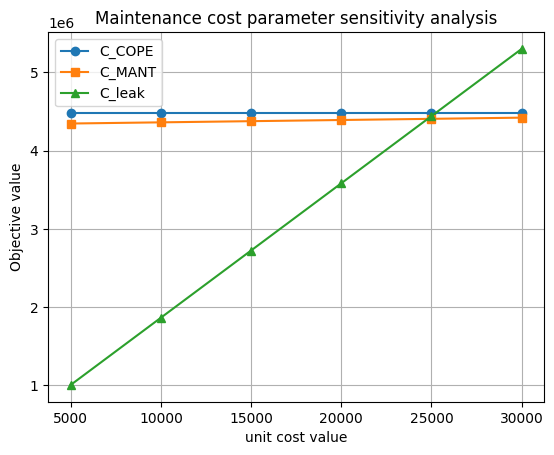

In [23]:
import matplotlib.pyplot as plt
from gurobipy import Model, GRB, quicksum

# 固定参数
N = 3
J = 5
T = 360 * 20
b_COPER = 4
b_MANT = 50
M1 = b_MANT + 1
M2 = 1e5
Delta_max = T
mu_COPER = 1.6
mu_MANT = 4.2
alpha_init = [0.005, 0.006, 0.0045]
alpha_COPER = [a / mu_COPER for a in alpha_init]
alpha_MANT = [a / mu_MANT for a in alpha_init]
V = [1, 1, 1]
K = [10**2 * 146 * V[i] / (8.314 * 293.15) for i in range(N)]
L_total = 20
P_init = [3.5, 3.5, 3.4]

def run_model(C_COPER, C_MANT, C_leak):
    B_CR = [(T*alpha_init[i]/(3.5-3.2)) * K[i] * C_leak for i in range(N)]

    mdl = Model('gas_system_maintenance')
    mdl.Params.OutputFlag = 0

    x_COPER = mdl.addVars(N, J, vtype=GRB.BINARY)
    x_MANT = mdl.addVars(N, J, vtype=GRB.BINARY)
    y_COPER = mdl.addVars(N, J, lb=0)
    y_MANT = mdl.addVars(N, J, lb=0)
    y_INIT = mdl.addVars(N, J, lb=0)
    t = mdl.addVars(N, J+1, vtype=GRB.CONTINUOUS)
    t_END = mdl.addVars(N, J, vtype=GRB.CONTINUOUS)
    R = mdl.addVars(N, J, lb=0)

    for i in range(N):
        mdl.addConstr(t[i, J] == T)

    def Delta(i,k):
        return t[i,k+1] - t[i,k]

    for i in range(N):
        for k in range(J):
            mdl.addConstr(t_END[i, k] == t[i, k] + b_COPER * x_COPER[i, k] + b_MANT * x_MANT[i, k])

    for i in range(N):
        for k in range(J-1):
            mdl.addConstr(t[i, k] <= t[i, k+1])

    for i in range(N):
        for k in range(J):
            mdl.addConstr(t[i, k+1] >= t_END[i, k] - M1 * (1 - x_COPER[i,k] - x_MANT[i,k]))

    for i in range(N):
        for k in range(J):
            mdl.addConstr(x_COPER[i,k] + x_MANT[i,k] <= 1)

    mdl.addConstr(quicksum(x_COPER[i,k] + x_MANT[i,k] for i in range(N) for k in range(J)) <= L_total)

    for i in range(N):
        for k in range(J):
            mdl.addConstr(y_COPER[i,k] <= Delta(i,k))
            mdl.addConstr(y_COPER[i,k] <= Delta_max * x_COPER[i,k])
            mdl.addConstr(y_COPER[i,k] >= Delta(i,k) - Delta_max * (1 - x_COPER[i,k]))

            mdl.addConstr(y_MANT[i,k] <= Delta(i,k))
            mdl.addConstr(y_MANT[i,k] <= Delta_max * x_MANT[i,k])
            mdl.addConstr(y_MANT[i,k] >= Delta(i,k) - Delta_max * (1 - x_MANT[i,k]))

            mdl.addConstr(y_INIT[i,k] <= Delta(i,k))
            mdl.addConstr(y_INIT[i,k] <= Delta_max * (1 - x_COPER[i,k] - x_MANT[i,k]))
            mdl.addConstr(y_INIT[i,k] >= Delta(i,k) - Delta_max * (x_COPER[i,k] + x_MANT[i,k]))

    for i in range(N):
        for k in range(J):
            mdl.addConstr(R[i,k] == C_leak * K[i] * (Delta(i,k) * alpha_init[i] - alpha_COPER[i] * y_COPER[i,k] - alpha_MANT[i] * y_MANT[i,k] - alpha_init[i] * y_INIT[i,k]))

    action_cost = quicksum(C_COPER * x_COPER[i,k] + C_MANT * x_MANT[i,k] for i in range(N) for k in range(J))
    BasicCR_cost = quicksum(B_CR[i] for i in range(N))
    leakage_cost_reduction = quicksum(R[i,k] for i in range(N) for k in range(J))

    mdl.setObjective(action_cost + BasicCR_cost - leakage_cost_reduction, GRB.MINIMIZE)
    mdl.optimize()

    if mdl.status == GRB.OPTIMAL:
        return mdl.objVal
    else:
        return None

# 成本参数测试范围
cost_values = list(range(5000, 35000, 5000))

ccoper_objs = []
cmant_objs = []
cleak_objs = []

fixed_C_COPER = 15600
fixed_C_MANT = 48000
fixed_C_leak = 0.1 * 25200

for val in cost_values:
    ccoper_objs.append(run_model(val, fixed_C_MANT, fixed_C_leak))

for val in cost_values:
    cmant_objs.append(run_model(fixed_C_COPER, val, fixed_C_leak))

# cleak稍作缩放方便观察
for val in cost_values:
    cleak_scaled = val * 0.1  # 根据实际比例调整
    cleak_objs.append(run_model(fixed_C_COPER, fixed_C_MANT, cleak_scaled))

import matplotlib.pyplot as plt

plt.plot(cost_values, ccoper_objs, marker='o', label='C_COPE')
plt.plot(cost_values, cmant_objs, marker='s', label='C_MANT')
plt.plot(cost_values, cleak_objs, marker='^', label='C_leak')

plt.xlabel('unit cost value')
plt.ylabel('Objective value')
plt.title('Maintenance cost parameter sensitivity analysis')
plt.legend()
plt.grid(True)
plt.show()


In [21]:
import numpy as np
import plotly.graph_objs as go
from plotly.offline import plot

# 设定离散的成本参数范围，可以调整点的密度
cost_vals = np.linspace(5000, 30000, 6)

C_COPER_grid, C_MANT_grid = np.meshgrid(cost_vals, cost_vals)
C_LEAK_fixed = 0.1 * 25200  # 固定泄漏成本，或者你可改为网格调节多个

Z = np.zeros_like(C_COPER_grid)

# 批量计算目标值
for i in range(C_COPER_grid.shape[0]):
    for j in range(C_COPER_grid.shape[1]):
        C_COPER_val = C_COPER_grid[i,j]
        C_MANT_val = C_MANT_grid[i,j]
        obj_val = run_model(C_COPER_val, C_MANT_val, C_LEAK_fixed)
        if obj_val is None:
            obj_val = np.nan
        Z[i,j] = obj_val

# 创建三维曲面
surface = go.Surface(
    x=C_COPER_grid,
    y=C_MANT_grid,
    z=Z,
    colorscale='Viridis',
    colorbar=dict(title='目标值'),
    contours = {
        "z": {"show": True, "start": np.nanmin(Z), "end": np.nanmax(Z), "size": 5000}
    }
)

layout = go.Layout(
    title='C_COPER 和 C_MANT 对目标值影响的三维曲面',
    scene=dict(
        xaxis_title='C_COPER 单位成本',
        yaxis_title='C_MANT 单位成本',
        zaxis_title='目标值'
    ),
    width=700,
    height=600
)

fig = go.Figure(data=[surface], layout=layout)
plot(fig)  # 生成html文件并自动打开浏览器显示


'temp-plot.html'